In [7]:
%%capture
!pip3 install mne numpy pandas
import json
from pathlib import Path
import pandas as pd
import numpy as np
import mne

DATA_DIR = Path("caueeg-dataset")

In [8]:
with open(DATA_DIR / "annotation.json") as f:
    annotation = json.load(f)

print("dataset_name:", annotation["dataset_name"])
print("num subjects:", len(annotation["data"]))
print("\n21-channel signal header (EDF channel order):")
print(annotation["signal_header"])

annotation_df = pd.DataFrame(annotation["data"])
annotation_df.head()


dataset_name: CAUEEG dataset
num subjects: 1379

21-channel signal header (EDF channel order):
['Fp1-AVG', 'F3-AVG', 'C3-AVG', 'P3-AVG', 'O1-AVG', 'Fp2-AVG', 'F4-AVG', 'C4-AVG', 'P4-AVG', 'O2-AVG', 'F7-AVG', 'T3-AVG', 'T5-AVG', 'F8-AVG', 'T4-AVG', 'T6-AVG', 'FZ-AVG', 'CZ-AVG', 'PZ-AVG', 'EKG', 'Photic']


,serial,age,symptom
0,00001,78,"[mci, mci_amnestic, mci_amnestic_rf]"
1,00002,56,"[normal, smi]"
2,00003,93,"[mci, mci_vascular]"
3,00004,78,"[dementia, ad, load]"
4,00005,75,"[mci, mci_amnestic, mci_amnestic_ef, mci_multi..."


In [9]:
# Age distribution and most common leaf symptom labels
print("Age: min={}, max={}, mean={:.1f}".format(
    annotation_df["age"].min(), annotation_df["age"].max(), annotation_df["age"].mean()
))

leaf_symptom = annotation_df["symptom"].apply(lambda s: s[-1])
leaf_symptom.value_counts().head(15)


Age: min=23, max=96, mean=70.8


symptom
cb_normal            260
load                 189
smi                  186
mci_amnestic_ef      144
mci_amnestic_rf      110
sivd                  79
tga                   72
mci_vascular          70
mci_amnestic          63
parkinson_disease     63
eoad                  41
parkinson_synd        30
mci_non_amnestic      16
nph                   13
hc_normal             11
Name: count, dtype: int64

In [10]:
for task_file in ["abnormal.json", "dementia.json"]:
    with open(DATA_DIR / task_file) as f:
        task = json.load(f)
    print(f"--- {task_file} ---")
    print("task_name:", task["task_name"])
    print("description:", task["task_description"])
    print("classes:", task["class_label_to_name"])
    print("split sizes: train={}, val={}, test={}".format(
        len(task["train_split"]), len(task["validation_split"]), len(task["test_split"])
    ))
    print()

with open(DATA_DIR / "abnormal.json") as f:
    abnormal = json.load(f)
pd.DataFrame(abnormal["train_split"]).head()


--- abnormal.json ---
task_name: CAUEEG-Abnormal benchmark
description: Classification of [Normal] and [Abnormal] symptoms
classes: ['Normal', 'Abnormal']
split sizes: train=1107, val=136, test=136

--- dementia.json ---
task_name: CAUEEG-Dementia benchmark
description: Classification of [Normal], [MCI], and [Dementia] symptoms.
classes: ['Normal', 'MCI', 'Dementia']
split sizes: train=950, val=119, test=118



,serial,age,symptom,class_name,class_label
0,01258,77,"[dementia, vd, sivd]",Abnormal,1
1,00836,80,"[normal, smi]",Normal,0
2,00761,75,"[dementia, ad, load]",Abnormal,1
3,01061,58,"[normal, cb_normal]",Normal,0
4,00796,92,"[dementia, ad, load]",Abnormal,1


In [11]:
serial = "00001"
edf_path = DATA_DIR / "signal" / "edf" / f"{serial}.edf"

raw = mne.io.read_raw_edf(edf_path, preload=True, verbose="ERROR")

print("channels:", raw.ch_names)
print("sampling rate (Hz):", raw.info["sfreq"])
print("n_samples:", raw.n_times)
print("duration (s):", raw.n_times / raw.info["sfreq"])

data, times = raw.get_data(return_times=True)
print("data shape:", data.shape)
data[:5, :5]


channels: ['Fp1-AVG', 'F3-AVG', 'C3-AVG', 'P3-AVG', 'O1-AVG', 'Fp2-AVG', 'F4-AVG', 'C4-AVG', 'P4-AVG', 'O2-AVG', 'F7-AVG', 'T3-AVG', 'T5-AVG', 'F8-AVG', 'T4-AVG', 'T6-AVG', 'FZ-AVG', 'CZ-AVG', 'PZ-AVG', 'EKG', 'Photic']
sampling rate (Hz): 200.0
n_samples: 145600
duration (s): 728.0
data shape: (21, 145600)


array([[ 0.0e+00, -1.1e-05, -1.3e-05, -1.1e-05, -7.0e-06],
       [ 2.9e-05,  3.3e-05,  3.4e-05,  3.6e-05,  3.8e-05],
       [-3.0e-06, -6.0e-06, -3.0e-06, -1.0e-06, -3.0e-06],
       [ 0.0e+00,  2.0e-06,  3.0e-06,  2.0e-06, -2.0e-06],
       [-1.0e-06, -2.0e-06, -3.0e-06, -3.0e-06, -6.0e-06]])

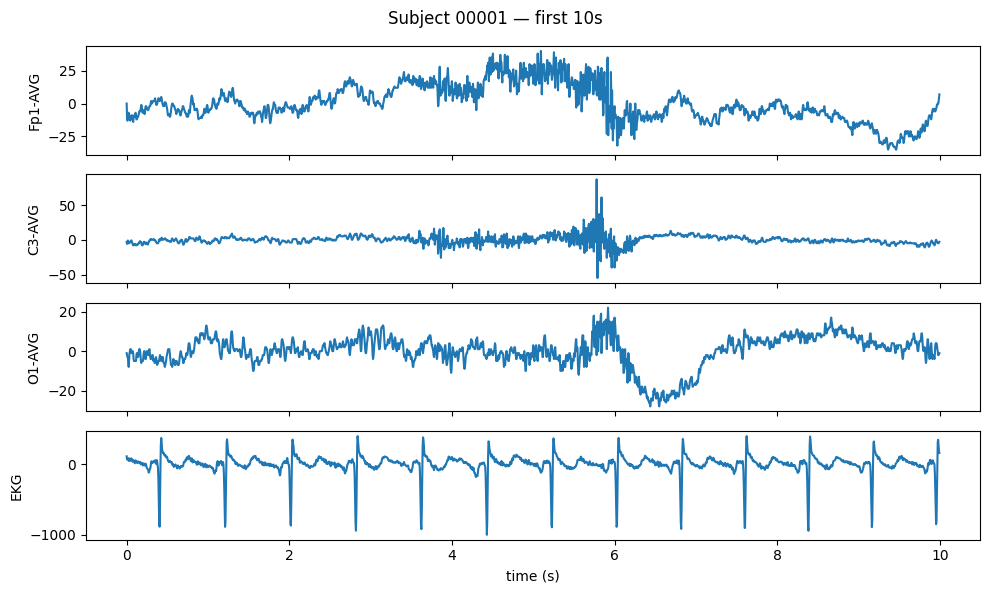

In [12]:
# Plot the first 10 seconds of a few EEG channels
%matplotlib inline
import matplotlib.pyplot as plt

seconds = 10
n_samples = int(seconds * raw.info["sfreq"])
channels_to_plot = ["Fp1-AVG", "C3-AVG", "O1-AVG", "EKG"]

fig, axes = plt.subplots(len(channels_to_plot), 1, figsize=(10, 6), sharex=True)
for ax, ch in zip(axes, channels_to_plot):
    idx = raw.ch_names.index(ch)
    ax.plot(times[:n_samples], data[idx, :n_samples] * 1e6)
    ax.set_ylabel(ch)
axes[-1].set_xlabel("time (s)")
fig.suptitle(f"Subject {serial} — first {seconds}s")
plt.tight_layout()
plt.show()


In [13]:
with open(DATA_DIR / "event" / f"{serial}.json") as f:
    events = json.load(f)

events_df = pd.DataFrame(events, columns=["sample_index", "label"])
events_df["time_s"] = events_df["sample_index"] / raw.info["sfreq"]
events_df.head(15)


,sample_index,label,time_s
0,0,Start Recording,0.00
1,0,New Montage - Montage 002,0.00
2,36396,Eyes Open,181.98
3,72518,Eyes Closed,362.59
4,73862,Eyes Open,369.31
5,75248,Eyes Closed,376.24
6,76728,swallowing,383.64
7,77978,Eyes Open,389.89
8,79406,Eyes Closed,397.03
9,79996,Photic On - 3.0 Hz,399.98


In [14]:
with open(DATA_DIR / "dementia.json") as f:
    dementia = json.load(f)

dementia_df = pd.concat([
    pd.DataFrame(dementia["train_split"]).assign(split="train"),
    pd.DataFrame(dementia["validation_split"]).assign(split="validation"),
    pd.DataFrame(dementia["test_split"]).assign(split="test"),
], ignore_index=True).sort_values("serial").reset_index(drop=True)

print("classes:", dementia["class_label_to_name"])
print("total labeled subjects:", len(dementia_df))
dementia_df.head(10)


classes: ['Normal', 'MCI', 'Dementia']
total labeled subjects: 1187


,serial,age,symptom,class_name,class_label,split
0,00001,78,"[mci, mci_amnestic, mci_amnestic_rf]",MCI,1,test
1,00002,56,"[normal, smi]",Normal,0,train
2,00003,93,"[mci, mci_vascular]",MCI,1,train
3,00004,78,"[dementia, ad, load]",Dementia,2,test
4,00005,75,"[mci, mci_amnestic, mci_amnestic_ef, mci_multi...",MCI,1,train
5,00006,78,"[dementia, ad, load]",Dementia,2,train
6,00007,80,"[dementia, ad, load]",Dementia,2,train
7,00008,66,"[normal, cb_normal]",Normal,0,test
8,00011,70,"[mci, mci_amnestic, mci_amnestic_ef]",MCI,1,train
9,00012,88,"[normal, smi]",Normal,0,train


chosen subjects per class: {'Normal': ['00002', '00008'], 'MCI': ['00001', '00003'], 'Dementia': ['00004', '00006']}


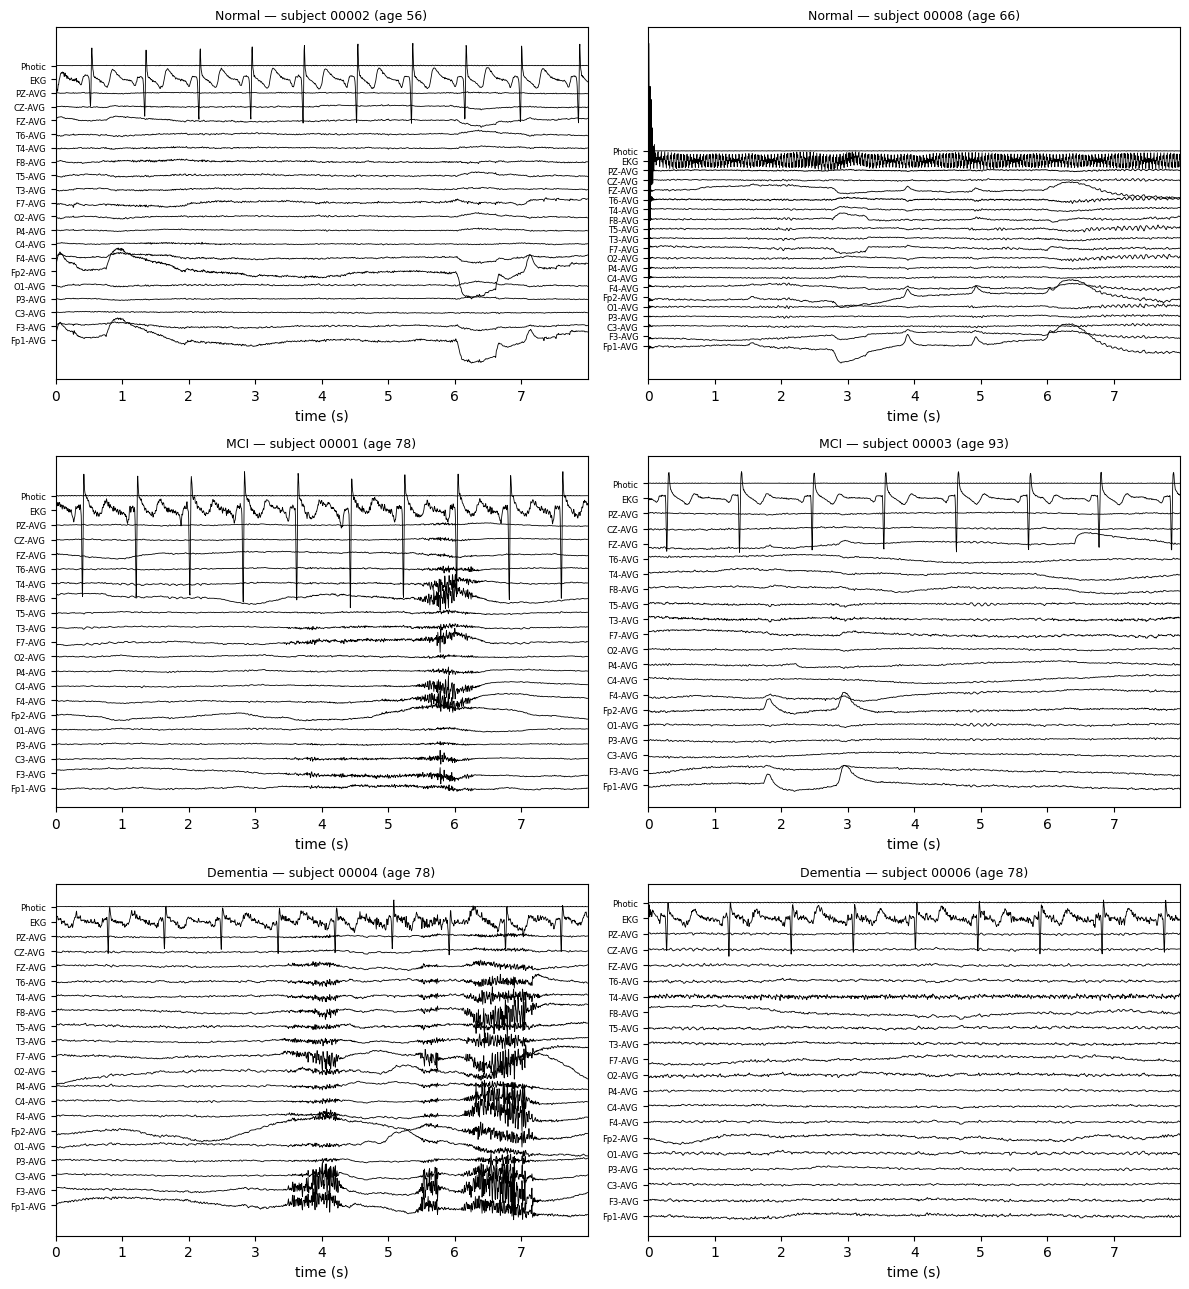

In [15]:
def load_eeg_snippet(serial_id, duration_s=8):
    edf_path = DATA_DIR / "signal" / "edf" / f"{serial_id}.edf"
    raw = mne.io.read_raw_edf(edf_path, preload=False, verbose="ERROR")
    raw.pick(mne.pick_types(raw.info, eeg=True))
    sfreq = raw.info["sfreq"]
    n_samples = int(duration_s * sfreq)
    data = raw.get_data(start=0, stop=n_samples)
    return data, raw.ch_names, sfreq


def plot_eeg_stack(ax, data, ch_names, sfreq, offset_uv=150, title=""):
    n_ch, n_samp = data.shape
    times = np.arange(n_samp) / sfreq
    for i, ch in enumerate(ch_names):
        trace_uv = data[i] * 1e6
        trace_uv = trace_uv - trace_uv.mean()
        ax.plot(times, trace_uv + i * offset_uv, linewidth=0.6, color="black")
    ax.set_yticks([i * offset_uv for i in range(n_ch)])
    ax.set_yticklabels(ch_names, fontsize=6)
    ax.set_xlabel("time (s)")
    ax.set_title(title, fontsize=9)
    ax.set_xlim(0, times[-1])


class_names = dementia["class_label_to_name"]
examples = {
    cname: dementia_df.loc[dementia_df["class_name"] == cname, "serial"].iloc[:2].tolist()
    for cname in class_names
}
print("chosen subjects per class:", examples)

fig, axes = plt.subplots(len(class_names), 2, figsize=(12, 13))
for row, cname in enumerate(class_names):
    for col, ex_serial in enumerate(examples[cname]):
        data, ch_names, sfreq = load_eeg_snippet(ex_serial)
        age = dementia_df.loc[dementia_df["serial"] == ex_serial, "age"].iloc[0]
        plot_eeg_stack(axes[row, col], data, ch_names, sfreq,
                        title=f"{cname} — subject {ex_serial} (age {age})")
plt.tight_layout()
plt.show()
